# **Ambient Clinical Scribe**



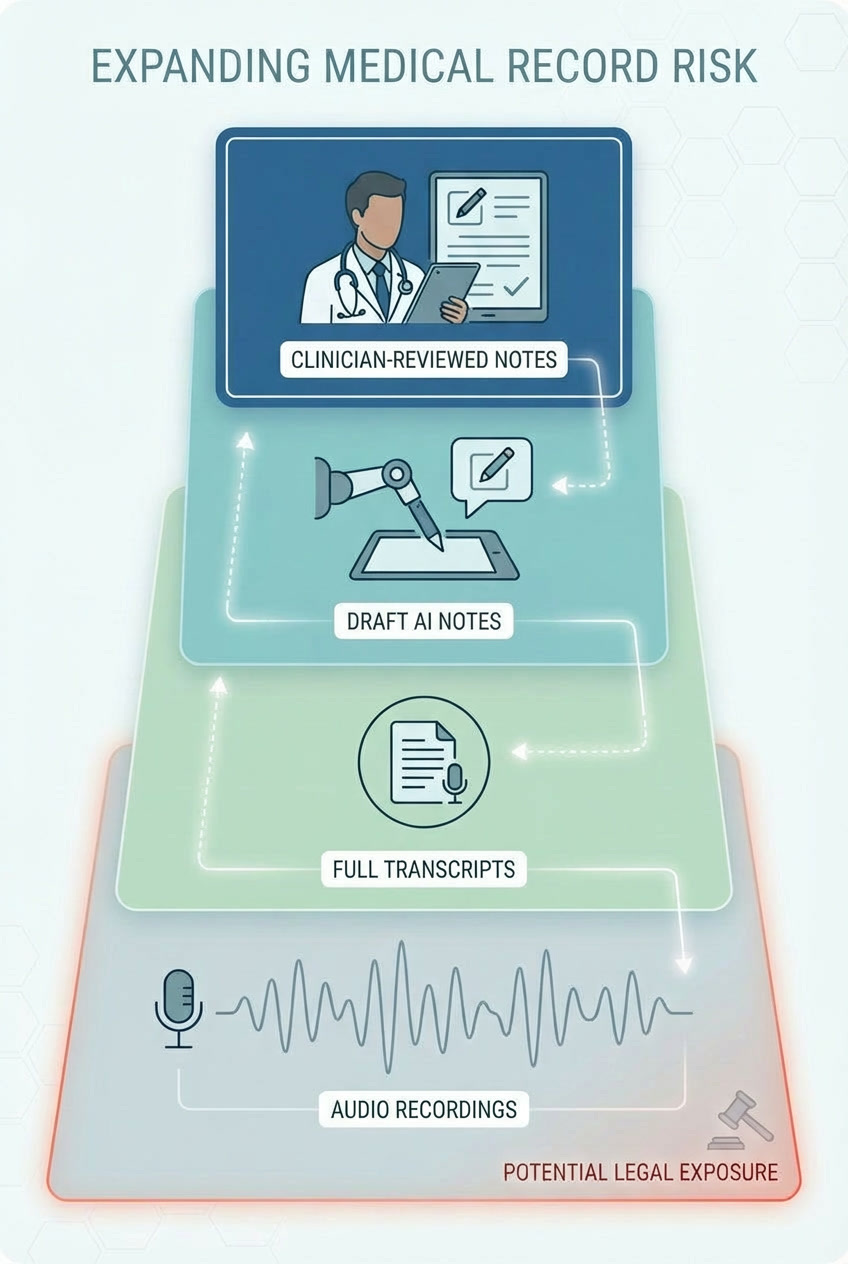


Turns a doctor-patient conversation (audio or transcript) into a structured
SOAP note, then cross-checks every claim in the note against the source
transcript and flags anything that isn't directly supported.

This is a documentation aid, not a diagnostic tool. The clinician reviews
and signs off on the final note.

In [1]:
!pip install -q openai


In [32]:
from __future__ import annotations
import json
import re
from dataclasses import dataclass, field, asdict
from pathlib import Path
import getpass
from openai import OpenAI
from google.colab import files
import requests

In [14]:
WORKDIR = Path("/content/scribe")
WORKDIR.mkdir(exist_ok=True)

## **Configuration**

In [15]:
CHAT_MODEL = "~z-ai/glm-flash-latest"
BASE_URL =  "https://openrouter.ai/api/v1"
api_key ="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"
client = OpenAI(api_key=api_key, base_url=BASE_URL)

## **Data model**

In [16]:
@dataclass
class SoapNote:
    chief_complaint: str
    subjective: str
    objective: str
    assessment: str
    plan: str

    def as_text(self) -> str:
        return (
            f"Chief Complaint: {self.chief_complaint}\n\n"
            f"Subjective:\n{self.subjective}\n\n"
            f"Objective:\n{self.objective}\n\n"
            f"Assessment:\n{self.assessment}\n\n"
            f"Plan:\n{self.plan}"
        )
@dataclass
class ScribeResult:
    transcript: str
    note: SoapNote
    flags: list[str] = field(default_factory=list)


## **Transcription**

In [33]:
def transcribe_audio(path: str) -> str:
    with open(path, "rb") as f:
        result = client.audio.transcriptions.create(model="whisper-1", file=f)
    return result.text

In [17]:
def load_input(mode: str) -> str:
    if mode == "audio":
        uploaded = files.upload()
        path = next(iter(uploaded))
        return transcribe_audio(path)
    print("Paste the conversation transcript, then an empty line to finish:")
    lines = []
    while True:
        line = input()
        if not line and lines and not lines[-1]:
            break
        lines.append(line)
    return "\n".join(lines).strip()


## **Note extraction**

In [35]:
EXTRACTION_PROMPT = """You are assisting a clinician by drafting a SOAP note \
from a conversation transcript. Use only information present in the \
transcript -- do not infer test results, diagnoses, or plans that were not \
actually discussed.

Return JSON with exactly these keys: chief_complaint, subjective, \
objective, assessment, plan. Each value is a string. If a section has \
nothing to report from the transcript, write "Not discussed"."""

In [18]:
def extract_note(transcript: str) -> SoapNote:
  response = client.chat.completions.create(
    model=CHAT_MODEL,
    messages=[
        {"role": "system", "content": EXTRACTION_PROMPT},
        {"role": "user", "content": transcript},
    ],
    temperature=0.1,
    max_tokens=1500,
    response_format={"type": "json_object"},
    )
  data = json.loads(response.choices[0].message.content)
  return SoapNote(**{k: data.get(k, "Not discussed") for k in
                        ("chief_complaint", "subjective", "objective", "assessment", "plan")})

In [20]:
def _split_claims(note: SoapNote) -> list[str]:
    text = note.as_text()
    parts = re.split(r"(?<=[.!?])\s+|\n+", text)
    return [p.strip() for p in parts if len(p.strip()) > 15]

## **Discrepancy check via Jev**

Jev is a decision model, not a text generator -- it can't write the note
itself, but checking "is this claim supported by the transcript?" is
exactly the bounded yes/no decision it's built for, and it's faster and
cheaper here than routing the same check through the chat model.


In [36]:
JEV_ENDPOINT = "https://openrouter.ai/api/alpha/decisions"
JEV_MODEL = "typesafe/jev-1.14"
JEV_SUPPORT_THRESHOLD = 0.5
jev_api_key = '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'

In [29]:
def claim_supported(transcript: str, claim: str) -> float:
    response = requests.post(
        JEV_ENDPOINT,
        headers={
            "Authorization": f"Bearer {jev_api_key}",
            "Content-Type": "application/json",
        },
        json={
            "model": JEV_MODEL,
            "state": {"transcript": transcript, "claim": claim},
            "questions": {
                "supported": {
                    "type": "noul",
                    "instructions": "Is the claim directly supported by the transcript?",
                    "criteria": {
                        "true": "The transcript explicitly states or clearly implies the claim.",
                        "false": "The claim is not mentioned in the transcript or contradicts it.",
                    },
                }
            },
        },
        timeout=30,
    )
    if not response.ok:
        print(response.status_code, response.text)
    response.raise_for_status()
    return response.json()["answers"]["supported"]["noul"]

In [37]:
def _split_claims(note: SoapNote) -> list[str]:
    parts = re.split(r"(?<=[.!?])\s+|\n+", note.as_text())
    return [p.strip() for p in parts if len(p.strip()) > 15]

In [38]:
def flag_discrepancies(transcript: str, note: SoapNote) -> list[str]:
    flagged = []
    for claim in _split_claims(note):
        probability = claim_supported(transcript, claim)
        if probability < JEV_SUPPORT_THRESHOLD:
            flagged.append(f"{claim} (support probability: {probability:.2f})")
    return flagged

## **Run**

In [39]:
def run(mode: str = "text") -> ScribeResult:
    transcript = load_input(mode)
    note = extract_note(transcript)
    flags = flag_discrepancies(transcript, note)
    return ScribeResult(transcript=transcript, note=note, flags=flags)

In [40]:
def render(result: ScribeResult) -> str:
    out = [result.note.as_text()]
    if result.flags:
        out.append("\nFlagged for review:")
        out.extend(f"  - {f}" for f in result.flags)
    else:
        out.append("\nNo unsupported claims detected.")
    return "\n".join(out)

In [30]:
result = run(mode="text")
print(render(result))

Paste the conversation transcript, then an empty line to finish:
Doctor: What brings you in today? Patient: I've had a cough for about two weeks, no fever. Doctor: Any shortness of breath? Patient: No. I'm a non-smoker. Doctor: Lungs sound clear. Let's try a cough suppressant and recheck in a week.


Chief Complaint: Cough for approximately two weeks.

Subjective:
Patient reports a cough lasting about two weeks. Denies fever. Denies shortness of breath. Reports being a non-smoker.

Objective:
Lungs clear on auscultation.

Assessment:
Cough of approximately two weeks duration. No fever or shortness of breath reported; lung exam clear. No specific diagnosis was stated in the encounter.

Plan:
Start a cough suppressant. Recheck in one week.

No unsupported claims detected.
